In [1]:
import numpy as np
import pandas as pd

In [2]:
dataset = pd.read_csv('JezPrzymClass.csv')
dataset.shape

(59, 6)

In [3]:
dataset.head(5)

,Id,Keratella_cochlearis_tecta,Polyarthra_vulgaris,Pompholyx_sulcata,Mesocyclops_leuckarti,Lake_class
0,1,0.03,0.0,0.0,0.00,Oligohaline
1,2,0.08,0.0,0.0,0.09,Oligohaline
2,3,0.06,0.0,0.0,0.08,Oligohaline
3,4,0.04,0.0,0.0,0.14,Oligohaline
4,5,0.02,0.0,0.0,0.00,Oligohaline


In [4]:
dataset.describe()

,Id,Keratella_cochlearis_tecta,Polyarthra_vulgaris,Pompholyx_sulcata,Mesocyclops_leuckarti
count,59.000000,59.000000,59.000000,59.000000,59.000000
mean,30.000000,0.059831,0.000508,0.002203,0.066271
std,17.175564,0.069220,0.002216,0.007208,0.119624
min,1.000000,0.000000,0.000000,0.000000,0.000000
25%,15.500000,0.020000,0.000000,0.000000,0.000000
50%,30.000000,0.040000,0.000000,0.000000,0.000000
75%,44.500000,0.070000,0.000000,0.000000,0.090000
max,59.000000,0.320000,0.010000,0.030000,0.580000


In [5]:
dataset.groupby('Lake_class').size()

Lake_class
Freshwater             29
Freshwater-isolated     5
Mesohaline             10
Oligohaline            15
dtype: int64

In [6]:
y = dataset.iloc[:, -1].values
X = dataset.iloc[:, 1:-1].values

In [7]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y = le.fit_transform(y)

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

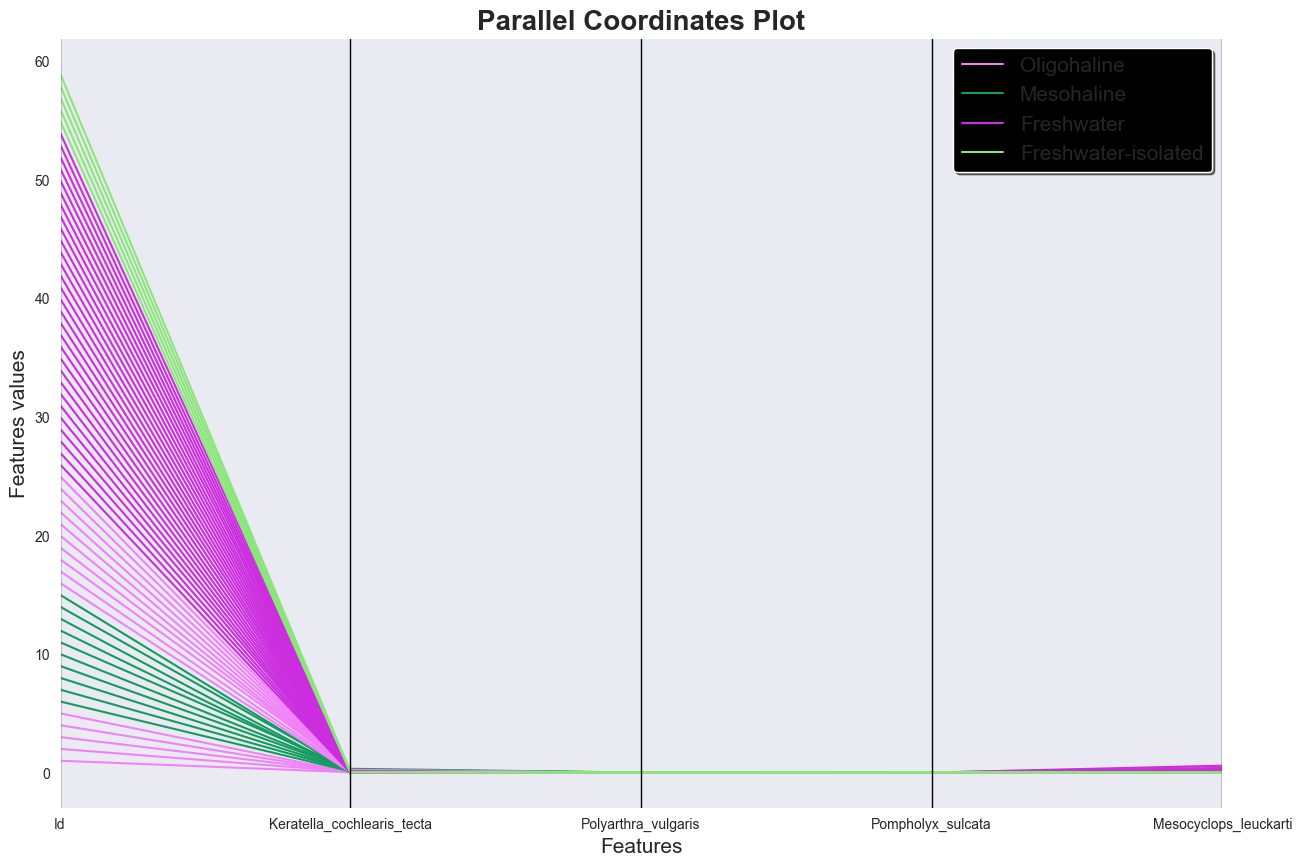

In [9]:
from pandas.plotting import parallel_coordinates
plt.figure(figsize=(15,10))
parallel_coordinates(dataset,"Lake_class")
plt.title('Parallel Coordinates Plot', fontsize=20, fontweight='bold')
plt.xlabel('Features', fontsize=15)
plt.ylabel('Features values', fontsize=15)
plt.legend(loc='best', prop={'size': 15}, frameon=True, shadow=True, facecolor='black', edgecolor='white')
plt.show()

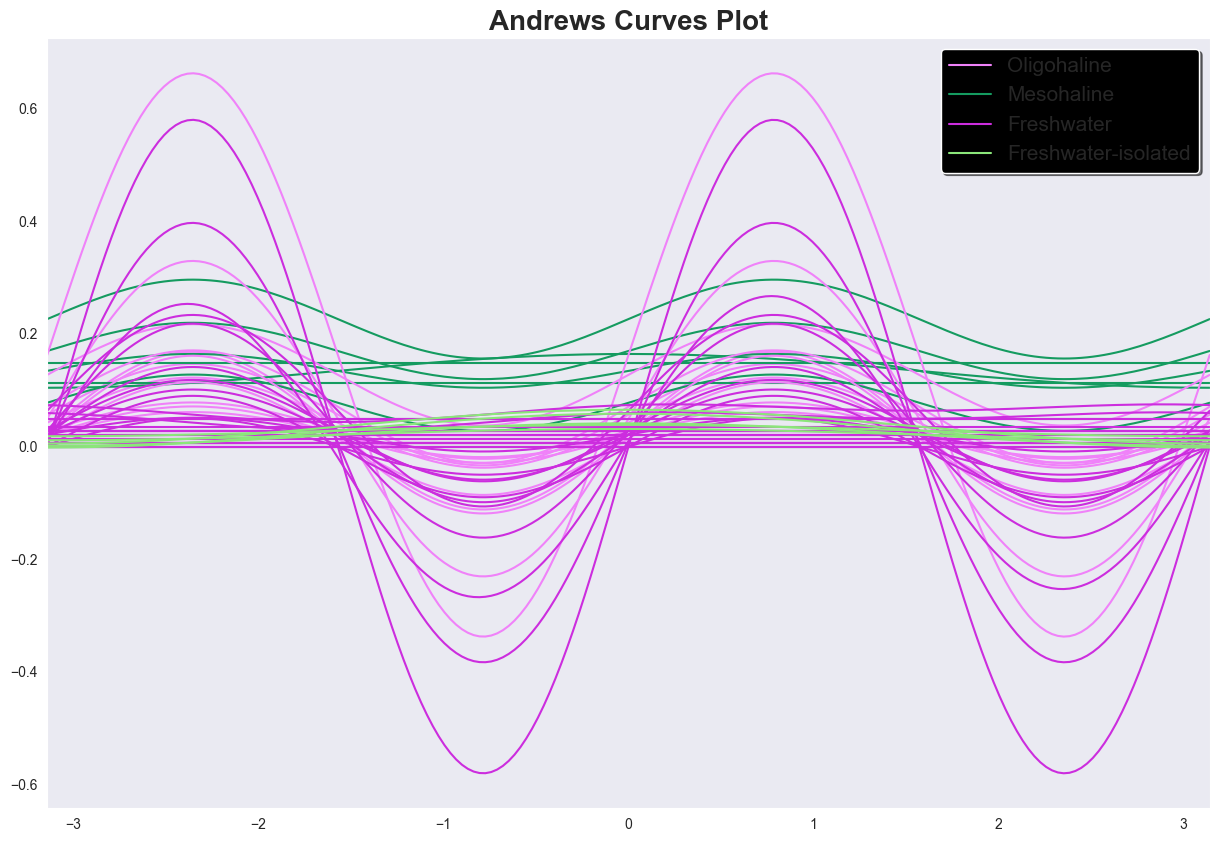

In [10]:
from pandas.plotting import andrews_curves
plt.figure(figsize=(15,10))
andrews_curves(dataset.drop("Id", axis=1), "Lake_class")
plt.title('Andrews Curves Plot', fontsize=20, fontweight='bold')
plt.legend(loc='best', prop={'size': 15}, frameon=True, shadow=True, facecolor="black", edgecolor="white")
plt.show()

<Figure size 640x480 with 0 Axes>

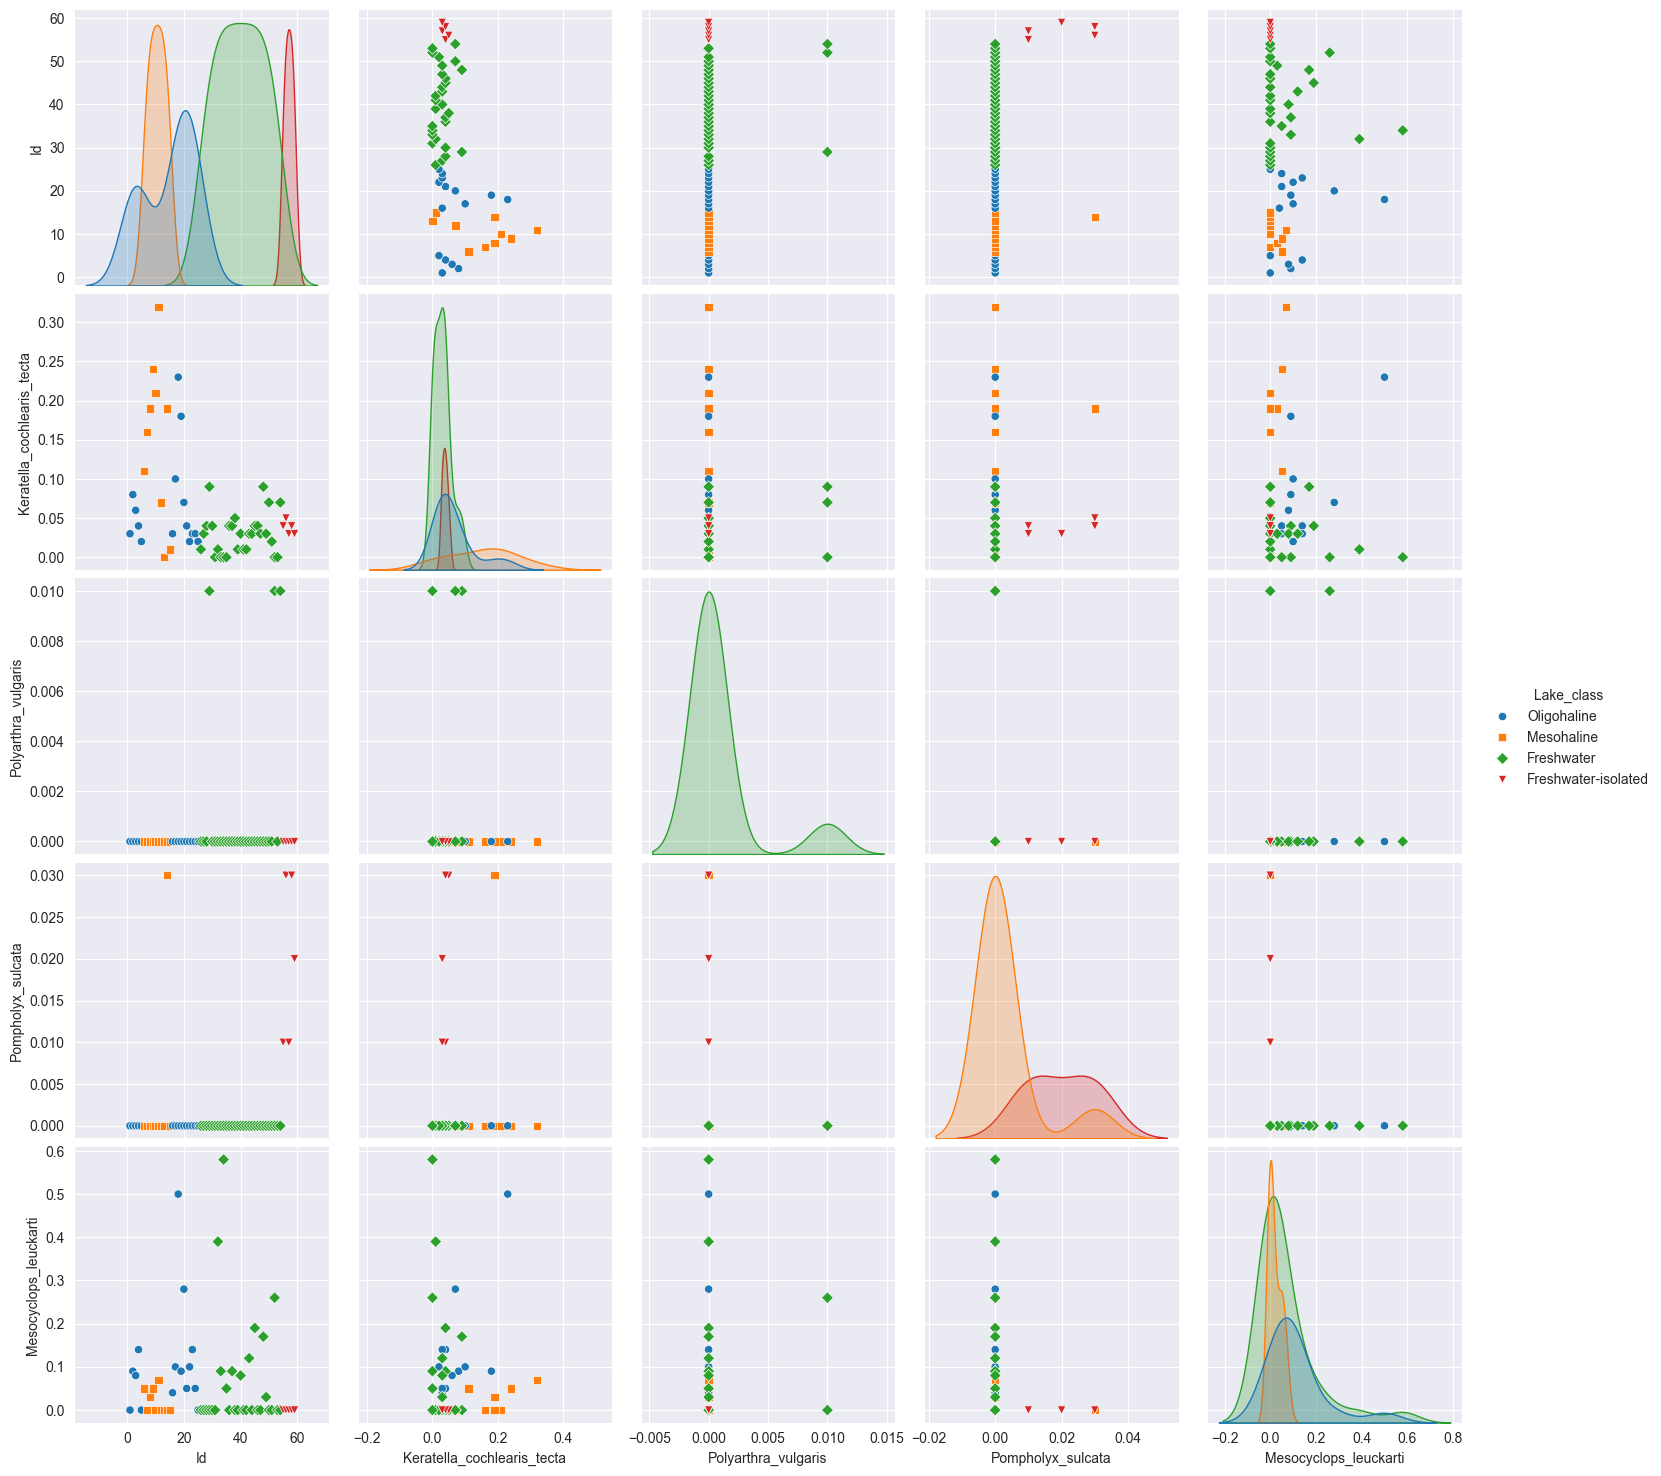

In [11]:
plt.figure()
sns.pairplot(dataset, hue="Lake_class", height=3, markers=["o", "s", "D", "v"])
plt.show()

<Figure size 640x480 with 0 Axes>

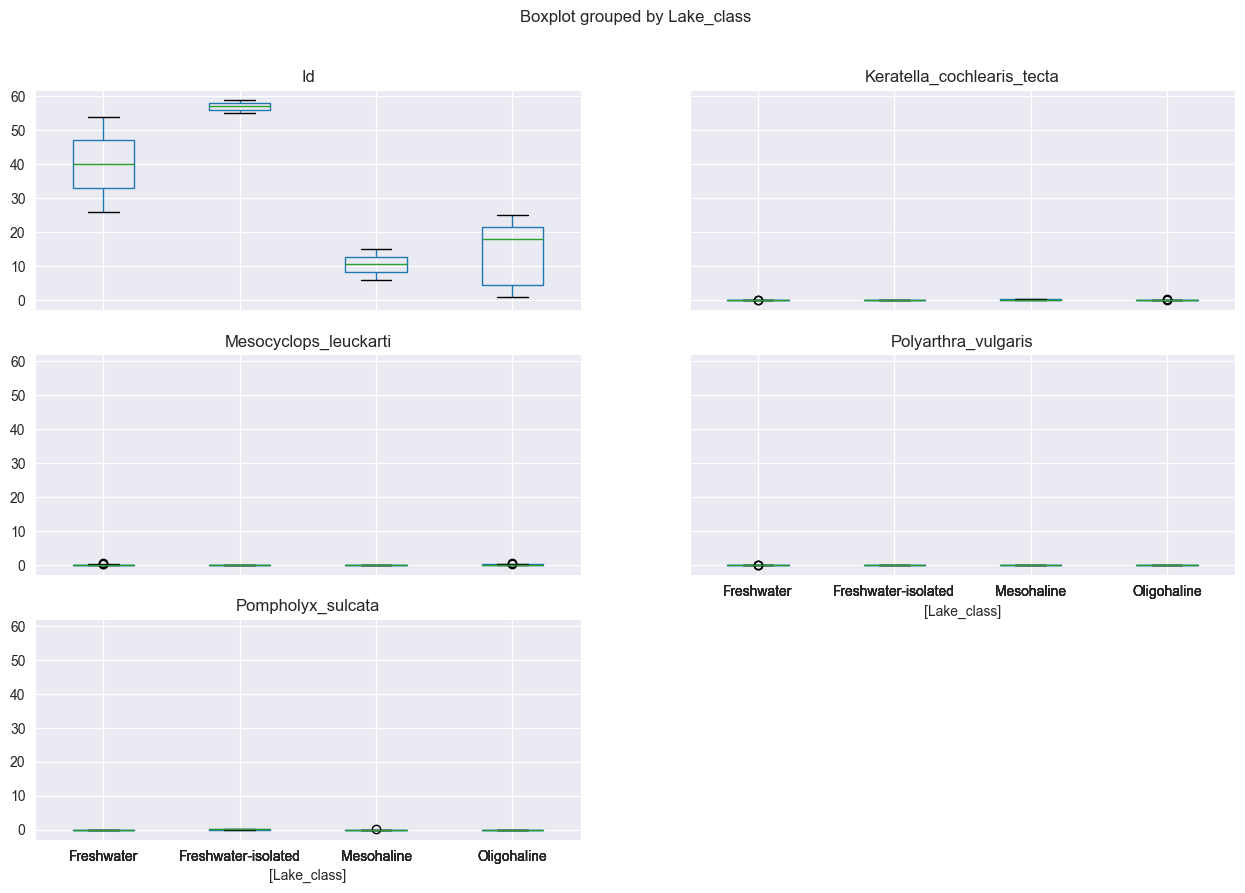

In [12]:
plt.figure()
dataset.boxplot(by="Lake_class", figsize=(15,10))
plt.show()

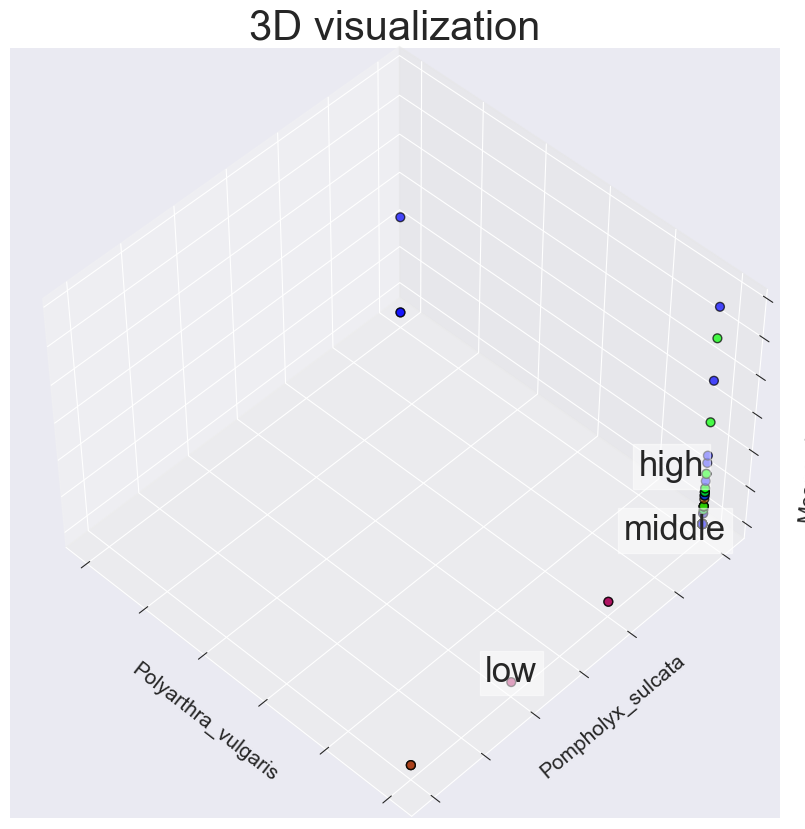

In [13]:
fig = plt.figure(1, figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d', elev=48, azim=134)
ax.scatter(X[:, 1], X[:, 2], X[:, 3], c=y,
           cmap=plt.cm.brg, edgecolor='k', s = 40, alpha = 0.7)

for name, label in [('high', 0), ('low', 1), ('middle', 2)]:
    ax.text3D(X[y == label, 1].mean(),
              X[y == label, 2].mean(),
              X[y == label, 3].mean(), name,
              horizontalalignment='center',
              bbox=dict(alpha =.5, edgecolor='w', facecolor='w'), size=25)

ax.set_title("3D visualization", fontsize=30)
ax.set_xlabel("Polyarthra_vulgaris", fontsize=15)
ax.xaxis.set_ticklabels([])
ax.set_ylabel("Pompholyx_sulcata", fontsize=15)
ax.yaxis.set_ticklabels([])
ax.set_zlabel("Mesocyclops_leuckarti", fontsize=15)
ax.zaxis.set_ticklabels([])
plt.show()

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
X_scaled = sc.fit_transform(X)
classifier = KNeighborsClassifier(n_neighbors=1)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

classifier.fit(X_train, y_train)

y_pred = classifier.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
cm

array([[4, 0, 1, 1],
       [0, 1, 0, 0],
       [1, 1, 0, 1],
       [1, 0, 0, 1]])

In [15]:
acc = accuracy_score(y_test, y_pred) * 100
print(f'Accuracy of out model is equal {str(round(acc, 2))} %.')

Accuracy of out model is equal 50.0 %.


In [ ]:
k_list = list(range(1,50,2))
cv_scores = []

for k in k_list:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train, y_train, cv=10, scoring='accuracy')
    cv_scores.append(scores.mean())

<Figure size 640x480 with 0 Axes>

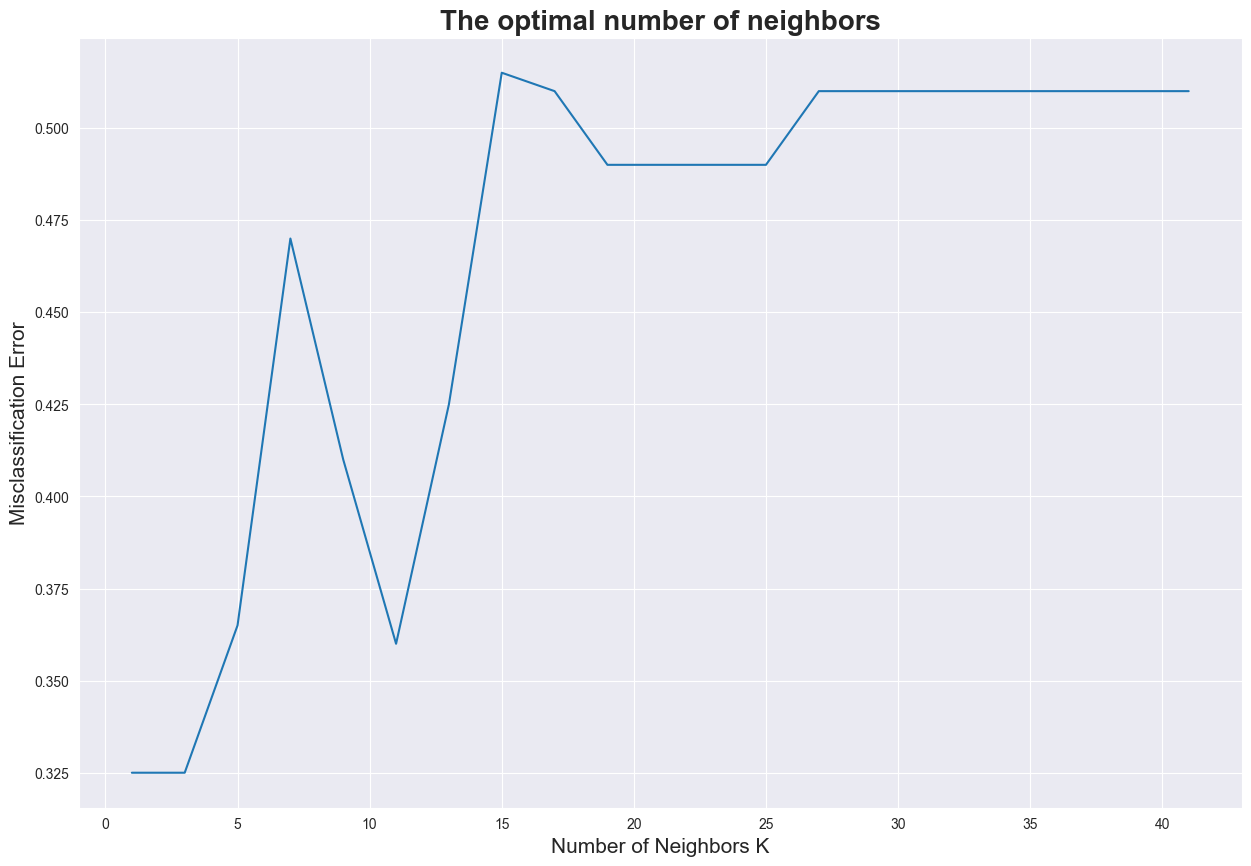

In [17]:
MSE = [1 - x for x in cv_scores]

plt.figure()
plt.figure(figsize=(15,10))
plt.title('The optimal number of neighbors', fontsize=20, fontweight='bold')
plt.xlabel ('Number of Neighbors K', fontsize=15)
plt.ylabel('Misclassification Error', fontsize=15)
sns.set_style("whitegrid")
plt.plot(k_list, MSE)

plt.show()

In [18]:
best_k = k_list[MSE.index(min(MSE))]
print("The optimal number of neighbors is %d." % best_k)

The optimal number of neighbors is 1.
